# 01 — Reproduce the audit on the six demo contracts

This notebook runs the full pipeline (solc compilation, AST, CFG and data-flow graph, slicing, GAT inference) on each demo contract using the committed weights `model.pth`. It reproduces the per-class confidences and localized lines reported in the manuscript.

**Prerequisites:** see `README.md`. The first run downloads solc 0.7.6 and 0.8.20 through py-solc-x.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
import platform, torch, networkx, sklearn, matplotlib
print("python", platform.python_version(), "| torch", torch.__version__,
      "| networkx", networkx.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__)

python 3.13.3 | torch 2.13.0+cpu | networkx 3.6.1 | scikit-learn 1.9.0 | matplotlib 3.11.1


## 1. Audit each contract with the saved weights

In [2]:
from auditor import audit_contract
import glob

contracts = sorted(glob.glob("demo_contracts/*.sol"))
for path in contracts:
    audit_contract(path, model_path="./model.pth", visualize=False)


[*] Starting security audit on: demo_contracts\ArithmeticSafe.sol
[*] Detected pragma version requirement. Using solc 0.8.20
[*] Compiling demo_contracts\ArithmeticSafe.sol...
[*] Generating contract semantic graph (AST + CFG + PDG)...
[+] Complete graph constructed: 73 nodes, 136 edges.
[*] Performing Program Slicing around security interest points...
[+] Sliced graph: 43 nodes, 77 edges (removed 30 clutter nodes).
[+] Loaded GNN model weights from ./model.pth

                 AUDIT SCAN REPORT                 
[Reentrancy] Confidence: 0.02%
[Timestamp Dependency] Confidence: 0.03%
[Arithmetic Error] Confidence: 0.04%
[+] SUCCESS: No vulnerabilities detected. Contract is clean.

[*] Starting security audit on: demo_contracts\ArithmeticVulnerable.sol
[*] Detected pragma version requirement. Using solc 0.7.6
[*] Compiling demo_contracts\ArithmeticVulnerable.sol...


[*] Generating contract semantic graph (AST + CFG + PDG)...
[+] Complete graph constructed: 73 nodes, 96 edges.
[*] Performing Program Slicing around security interest points...
[+] Sliced graph: 18 nodes, 18 edges (removed 55 clutter nodes).
[+] Loaded GNN model weights from ./model.pth

                 AUDIT SCAN REPORT                 
[Reentrancy] Confidence: 0.00%
[Timestamp Dependency] Confidence: 0.07%
[Arithmetic Error] Confidence: 99.88%
  >>> ALERT: Potential Arithmetic Error vulnerability detected!
      Unable to localize exact line (low node confidence).
--------------------------------------------------

[*] Starting security audit on: demo_contracts\ReentrancySafe.sol
[*] Detected pragma version requirement. Using solc 0.8.20
[*] Compiling demo_contracts\ReentrancySafe.sol...
[*] Generating contract semantic graph (AST + CFG + PDG)...
[+] Complete graph constructed: 59 nodes, 109 edges.
[*] Performing Program Slicing around security interest points...
[+] Sliced graph: 

  >>> Vulnerable Code Localization (GNN Node Saliency):
      [Line 015]: bal
      [Line 016]: require
--------------------------------------------------
[Timestamp Dependency] Confidence: 0.06%
[Arithmetic Error] Confidence: 0.67%

[*] Starting security audit on: demo_contracts\TimestampSafe.sol
[*] Detected pragma version requirement. Using solc 0.8.20
[*] Compiling demo_contracts\TimestampSafe.sol...
[*] Generating contract semantic graph (AST + CFG + PDG)...
[+] Complete graph constructed: 25 nodes, 40 edges.
[*] Performing Program Slicing around security interest points...
[+] Sliced graph: 19 nodes, 32 edges (removed 6 clutter nodes).
[+] Loaded GNN model weights from ./model.pth

                 AUDIT SCAN REPORT                 
[Reentrancy] Confidence: 0.02%
[Timestamp Dependency] Confidence: 28.82%
[Arithmetic Error] Confidence: 1.06%
[+] SUCCESS: No vulnerabilities detected. Contract is clean.

[*] Starting security audit on: demo_contracts\TimestampVulnerable.sol
[*] Dete

## 2. Visualized audit graphs

The three vulnerable contracts were rendered with `auditor.py --visualize`. Flagged nodes are red.

ReentrancyVulnerable


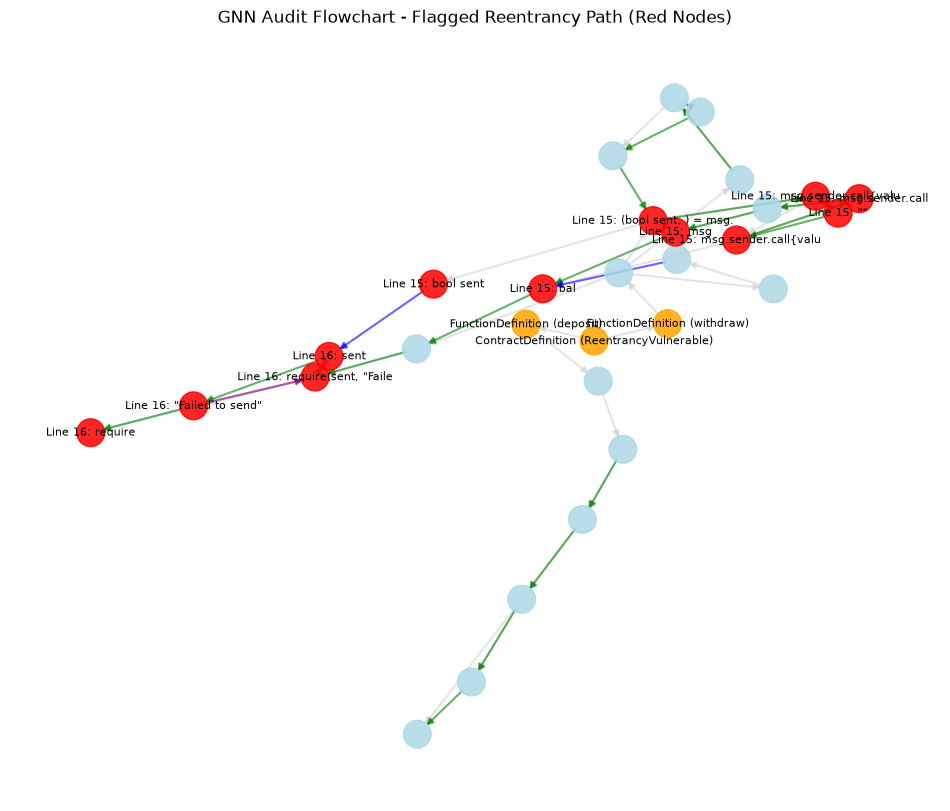

TimestampVulnerable


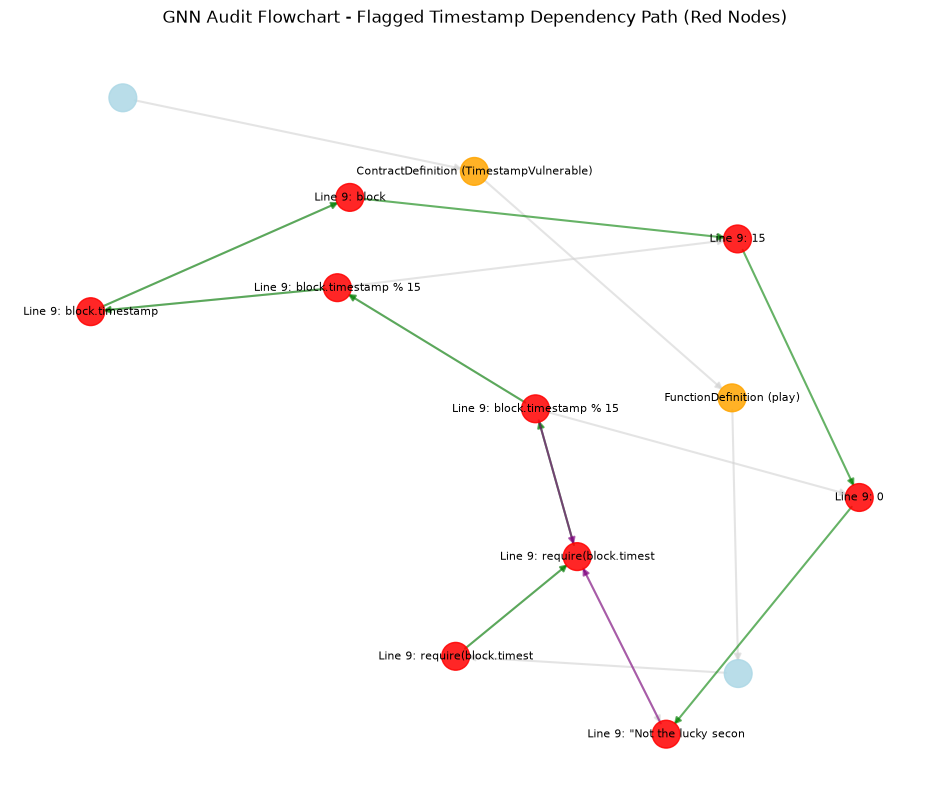

ArithmeticVulnerable


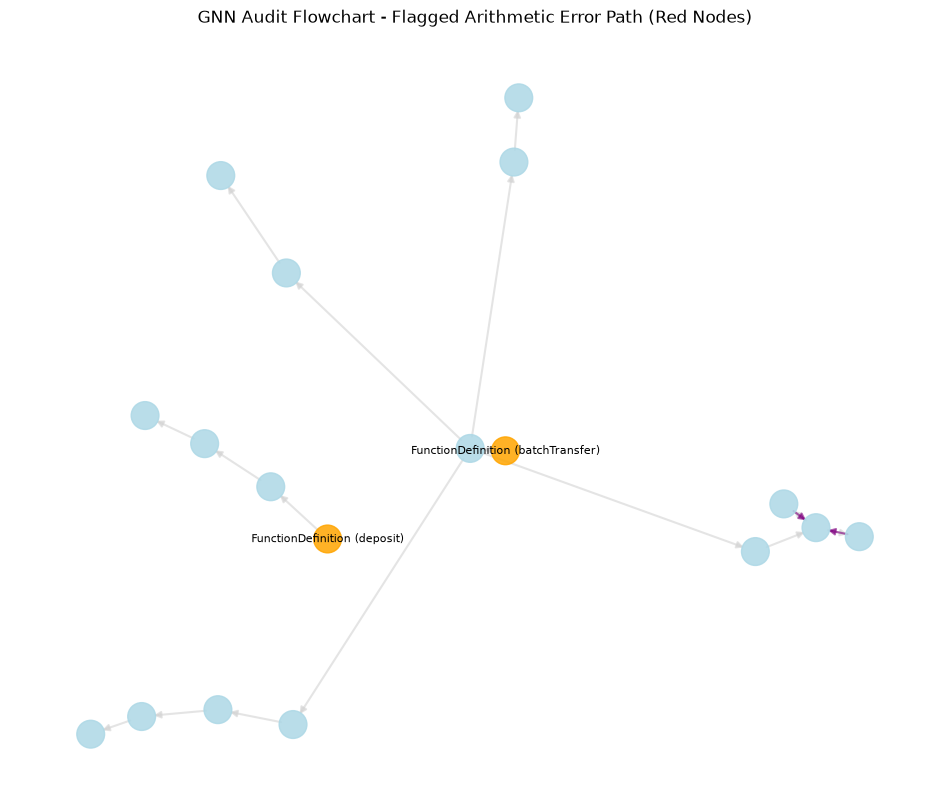

In [3]:
from IPython.display import Image, display
for name in ["ReentrancyVulnerable", "TimestampVulnerable", "ArithmeticVulnerable"]:
    print(name)
    display(Image(filename=f"figures/{name}_audit.png", width=600))

## 3. Notes on what this shows

* Confidences are sigmoid outputs of the classifier head, not calibrated probabilities.
* These contracts were also used to train `model.pth`, so this is an in-sample check. The held-out evaluation is in notebook 02.
* After the label fix recorded in `FAILURE_LOG.md`, the Timestamp contract is localized to line 9. The Arithmetic contract is still not localized.